# Calibration

**Idea:** a model that says "90% sure" should be right about 90% of the time. Temperature scaling adjusts the model's confidence without changing its predictions.


In [1]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

# Folders for the dataset and for saved results
from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive")  # data/ and outputs/ will now be created here
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)

Mounted at /content/drive
PyTorch version: 2.11.0+cpu


In [2]:
# CIFAR-10: 32x32 color pictures, 10 classes (plane, car, bird, ...)
mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
plain_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

In [3]:
full_train = datasets.CIFAR10("data", train=True, download=True, transform=plain_tf)
test_data = datasets.CIFAR10("data", train=False, download=True, transform=plain_tf)

# 10,000 images for training and 2,000 for validation (kept small so it runs fast on a CPU)
idx = np.random.permutation(len(full_train))
train_data = Subset(full_train, idx[:10000].tolist())
val_data = Subset(full_train, idx[10000:12000].tolist())

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64)
test_loader = DataLoader(test_data, batch_size=64)
print("train / val / test sizes:", len(train_data), len(val_data), len(test_data))

train / val / test sizes: 10000 2000 10000


In [4]:
# A small convolutional network for CIFAR-10
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

In [5]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Return (average loss, accuracy) of the model on a dataset."""
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            loss_sum += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

def train(model, loader, epochs=3, lr=1e-3, weight_decay=0.0, make_scheduler=None):
    """Train with Adam. Returns a table of per-epoch results and the training time."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        loss_sum, seen = 0.0, 0
        for x, y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            seen += len(y)
        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / seen, "val_loss": val_loss,
                        "val_acc": val_acc, "lr": optimizer.param_groups[0]["lr"]})
        print(f"epoch {epoch+1}/{epochs}  train_loss={loss_sum/seen:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")
        if scheduler:
            scheduler.step()
    return pd.DataFrame(history), time.time() - start

## Step 1: Train the CNN

In [6]:
model = SmallCNN()
history, secs = train(model, train_loader, epochs=2)

epoch 1/2  train_loss=1.7228  val_loss=1.4317  val_acc=0.4680
epoch 2/2  train_loss=1.3098  val_loss=1.2950  val_acc=0.5245


## Step 2: Get the model's raw outputs (logits)

In [7]:
def get_logits(model, loader, noise=0.0):
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            if noise > 0:
                x = x + noise * torch.randn_like(x)  # add random noise to the images
            all_logits.append(model(x))
            all_labels.append(y)
    return torch.cat(all_logits), torch.cat(all_labels)

val_logits, val_labels = get_logits(model, val_loader)
test_logits, test_labels = get_logits(model, test_loader)

## Step 3: Find the best temperature on the validation set

We try many temperatures and keep the one with the lowest loss. (Never pick it using the test set.)

In [8]:
best_T, best_loss = 1.0, float("inf")
for T in np.arange(0.5, 5.0, 0.05):
    loss = nn.functional.cross_entropy(val_logits / T, val_labels).item()
    if loss < best_loss:
        best_T, best_loss = T, loss
print("Best temperature:", round(float(best_T), 2))

Best temperature: 1.0


## Step 4: Measure calibration

**ECE** (expected calibration error) is the average gap between confidence and accuracy. Lower is better.

In [9]:
def ece(logits, labels, T=1.0, n_bins=10):
    probs = torch.softmax(logits / T, dim=1)
    conf, pred = probs.max(dim=1)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    total = 0.0
    for i in range(n_bins):
        in_bin = (conf > edges[i]) & (conf <= edges[i + 1])
        if in_bin.any():
            gap = abs(correct[in_bin].mean() - conf[in_bin].mean())
            total += in_bin.float().mean() * gap
    return float(total)

def summarize(name, logits, labels, T=1.0):
    return {"condition": name,
            "accuracy": (logits.argmax(1) == labels).float().mean().item(),
            "loss": nn.functional.cross_entropy(logits / T, labels).item(),
            "ece": ece(logits, labels, T)}

noisy_logits, noisy_labels = get_logits(model, test_loader, noise=0.10)

results = pd.DataFrame([
    summarize("clean, before scaling", test_logits, test_labels, 1.0),
    summarize("clean, after scaling", test_logits, test_labels, best_T),
    summarize("noisy, before scaling", noisy_logits, noisy_labels, 1.0),
])
results.to_csv("outputs/calibration_results.csv", index=False)
print(results)

               condition  accuracy      loss       ece
0  clean, before scaling    0.5296  1.303120  0.008638
1   clean, after scaling    0.5296  1.303120  0.008638
2  noisy, before scaling    0.5278  1.307252  0.008377


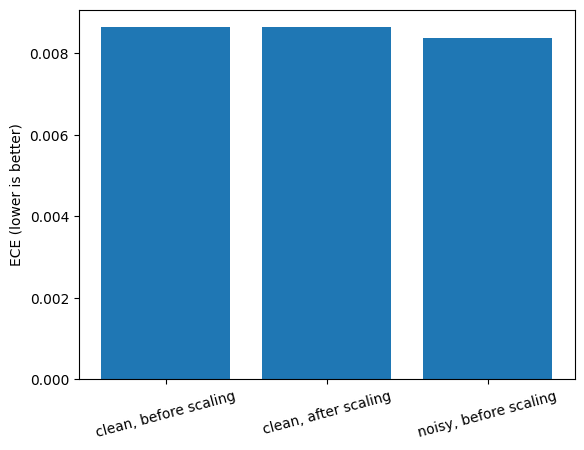

In [10]:
plt.bar(results["condition"], results["ece"])
plt.ylabel("ECE (lower is better)")
plt.xticks(rotation=15)
plt.savefig('outputs/calibration_ece.png')
plt.show()